# SARSA

In [2]:
import time 
import gymnasium as gym
from tqdm import tqdm  # tqdm es una libreria que muestra barra de progresos
import random
import numpy as np 
import matplotlib.pyplot as plt

print(gym.__version__)

1.3.0


In [4]:
# Crear ambiente
env = gym.make('CliffWalking-v1', render_mode = 'human')
# Probando un episodio
observation, _ = env.reset() 
done = False
for _ in range(20):
    #Escoger una acción random
    action = env.action_space.sample()  
    #Usar la acción en el ambiente
    observation, reward, terminated, truncated, info = env.step(action) 
    done = terminated or truncated

#Cerrar el ambiente    
env.close()

In [5]:
class Sarsa:
    """ Sarsa algorithm """
    def __init__(self, epsilon, epsilon_min, epsilon_decay, alpha, gamma, n_states, n_action):
        self.Q_table = np.zeros([n_states, n_action])  #  Inicializat la Q-table
        self.n_action = n_action  # numero de acciones
        self.alpha = alpha  # tasa de aprendizaje
        self.gamma = gamma  # factor de descuento
        self.epsilon = epsilon  # parametros e-greedy
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

    def take_action(self, state):  # Seleccionar la siguiente accion, especificamente epsilon-greedy
        if np.random.random() < self.epsilon:
            action = np.random.randint(self.n_action)
        else:
            action = np.argmax(self.Q_table[state])
        return action

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon*self.epsilon_min)

    def best_action(self, state):  # para imprimir la estrategia
        Q_max = np.max(self.Q_table[state])
        a = [0 for _ in range(self.n_action)]
        for i in range(self.n_action): 
            if self.Q_table[state, i] == Q_max:
                a[i] = 1
        return a

    def update(self, s0, a0, r, s1, a1):
        td_error = r + self.gamma * self.Q_table[s1, a1] - self.Q_table[s0, a0]
        self.Q_table[s0, a0] += self.alpha * td_error

Iteration 9: 100%|██████████| 200/200 [00:00<00:00, 1322.70it/s, episode=2000, return=-19.100, epsilon=0.010] 


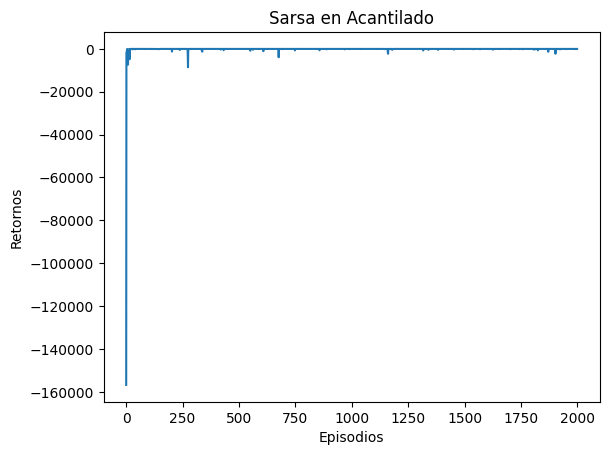

In [6]:
env = gym.make('CliffWalking-v1')

n_states = env.observation_space.n
n_actions = env.action_space.n
np.random.seed(0)
epsilon = 1
epsilon_decay = 0.995
epsilon_min = 0.01
alpha = 0.5
gamma = 0.99
agent = Sarsa(epsilon, epsilon_min, epsilon_decay, alpha, gamma, n_states, n_actions)
num_episodes = 2000  # Numero de secuencias el agente correra el ambiente

return_list = []  # guardar el retonro de cada secuencia
for i in range(10):  # mostrar 10 barras de progreso
    # Barra de progreso de la funcion tqdm
    with tqdm(total=int(num_episodes / 10), desc='Iteration %d' % i) as pbar:
        for i_episode in range(int(num_episodes / 10)):  # numero de secuencias para cada barra de progreso
            episode_return = 0
            state, _ = env.reset()
            action = agent.take_action(state)
            done = False
            while not done:
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                next_action = agent.take_action(next_state)
                episode_return += reward  
                agent.update(state,action,reward,next_state,next_action)
                state = next_state
                action = next_action
            agent.decay_epsilon()    
            return_list.append(episode_return)
            if (i_episode + 1) % 10 == 0:  # Imprimir el retorno promedio
                pbar.set_postfix({
                    'episode':
                    '%d' % (num_episodes / 10 * i + i_episode + 1),
                    'return':
                    '%.3f' % np.mean(return_list[-10:]),
                    'epsilon':
                    '%.3f' % agent.epsilon,
                })
            pbar.update(1)

episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('Sarsa en {}'.format('Acantilado'))
plt.show()

In [7]:
def print_agent(agent, env, action_meaning, disaster=[], end=[]):
    for i in range(env.unwrapped.shape[0]):
        for j in range(env.env.unwrapped.shape[1]):
            if (i * env.unwrapped.shape[1] + j) in disaster:
                print('****', end=' ')
            elif (i * env.unwrapped.shape[1] + j) in end:
                print('EEEE', end=' ')
            else:
                a = agent.best_action(i * env.unwrapped.shape[1] + j)
                pi_str = ''
                for k in range(len(action_meaning)):
                    pi_str += action_meaning[k] if a[k] > 0 else 'o'
                print(pi_str, end=' ')
        print()

action_meaning = ['^', '>', 'v', '<']
print('La estrategia obtenida por el algoritmo de Sarsa es：')
print_agent(agent, env, action_meaning, list(range(37, 47)), [47])

La estrategia obtenida por el algoritmo de Sarsa es：
o>oo o>oo o>oo o>oo o>oo o>oo o>oo o>oo oovo ooo< oovo oovo 
^ooo ^ooo ^ooo o>oo ^ooo o>oo ^ooo o>oo oovo o>oo o>oo oovo 
^ooo ^ooo ^ooo ^ooo ^ooo ^ooo o>oo o>oo o>oo ^ooo o>oo oovo 
^ooo **** **** **** **** **** **** **** **** **** **** EEEE 


In [8]:
np.set_printoptions(precision=4)
agent.Q_table

array([[ -73.6204,  -16.2381,  -92.5133,  -78.3067],
       [-103.5842,  -20.8857, -128.5834,  -56.8347],
       [ -73.7455,  -27.0383,  -73.8848,  -76.2082],
       [ -47.7604,  -26.3004,  -94.9065,  -76.4   ],
       [ -58.2919,  -18.4587, -320.3219,  -75.5626],
       [-122.9637,  -11.8999, -121.2935,  -75.1226],
       [ -56.3578,   -9.5618,  -59.5685, -130.2315],
       [ -64.2223,   -8.6483,  -59.8221,  -47.2791],
       [ -63.2377,  -60.3329,   -7.7255,  -72.7521],
       [ -60.3063,  -60.3632,  -60.3092,  -60.2878],
       [ -60.348 ,  -60.1   ,  -49.6851,  -60.2575],
       [ -60.0375,  -60.1122,  -45.73  ,  -60.0429],
       [ -15.7787,  -54.3429,  -94.8244,  -94.9254],
       [ -33.8944, -249.9452, -313.4973, -118.5842],
       [ -46.8421, -480.9577, -522.4338, -288.5049],
       [-416.2399,  -94.4394, -490.2495, -462.948 ],
       [ -12.8299, -208.952 , -437.8194, -453.314 ],
       [-287.839 ,  -56.4413, -460.5235, -378.8937],
       [ -59.2233, -112.8531, -484.2607, -335.

In [13]:

#Obtener estado inicial
env = gym.make('CliffWalking-v1', render_mode = 'human')
state, _ = env.reset()

for step in range(100):
    #Escoger la mejor acción de la q_table
    action = np.argmax(agent.Q_table[state])
    #Obtener s', r', donde e info
    state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    
    if done:
        break

#Cerrar ambiente        
env.close()